# 03 · Ingeniería de Características y Transformaciones no Lineales

## Justificación Financiera
La relación entre **Loan-to-Value (LTV)** y la severidad de pérdida (**LGD**) es marcadamente no lineal:
1. **Colchón de Colateral**: En tramos bajos de LTV ($< 60\%$), la garantía cubre con holgura el capital insoluto, costas judiciales e intereses moratorios.
2. **Aceleración de Quebranto en Garantías Deficitarias**: Al superar el 100% de LTV, la pérdida neta se acelera rápidamente, agravada por honorarios de remate y depreciación del activo.
3. **Inmuebles de Renta**: Los créditos de inversión (`purpose1 = 1`) tienden a ser abandonados más rápido durante crisis que la vivienda principal.

Variables construidas:
* $\log(\text{LTV})$: Comprime la asimetría positiva de valores atípicos.
* $\text{LTV}^2$: Modela el crecimiento cuadrático del quebranto en inmuebles *underwater*.
* Interacción $\text{LTV} \times \text{purpose1}$.
* Tramos regulatorios de LTV ($<60\%$, $60-80\%$, $80-100\%$, $>100\%$).

In [1]:
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sys.path.insert(0, str(Path("../src").resolve()))
from preprocessing import engineer_lgd_features

plt.style.use('seaborn-v0_8-whitegrid')

train_df = pd.read_csv("../data/processed/lgd_train.csv")
test_df = pd.read_csv("../data/processed/lgd_test.csv")
print(f"Cargadas particiones: Train ({len(train_df)}) y Test ({len(test_df)}).")

Cargadas particiones: Train (1453) y Test (364).


In [2]:
# Aplicar pipeline de ingeniería de variables
train_feat = engineer_lgd_features(train_df)
test_feat = engineer_lgd_features(test_df)

display(train_feat.head())

,LTV,purpose1,lgd_time,log_LTV,sqrt_LTV,LTV_sq,LTV_purpose1,LTV_bucket
0,0.753837,0,0.220387,-0.282579,0.868238,0.568271,0.000000,LTV_Mid_60-80
1,1.019531,1,0.596265,0.019343,1.009718,1.039444,1.019531,LTV_Underwater_>100
2,1.210152,0,0.999990,0.190746,1.100069,1.464467,0.000000,LTV_Underwater_>100
3,0.441861,0,0.033471,-0.816760,0.664726,0.195241,0.000000,LTV_Low_<60
4,0.487186,0,0.672945,-0.719109,0.697987,0.237350,0.000000,LTV_Low_<60


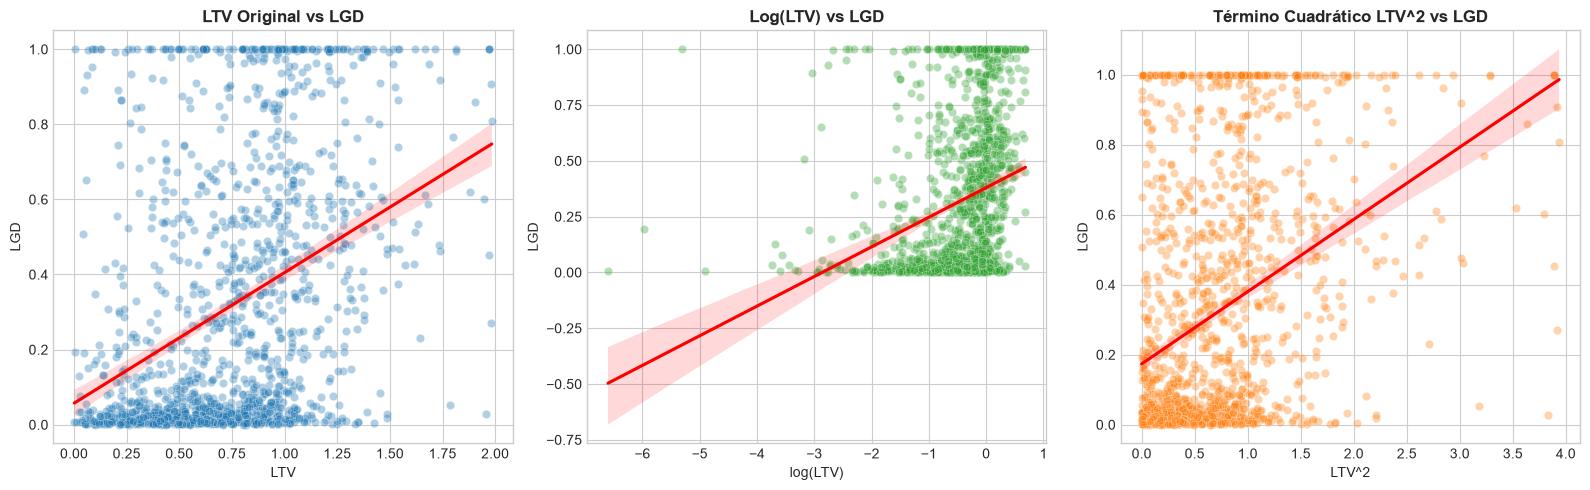

In [3]:
# Visualización de transformaciones frente a la LGD
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

sns.scatterplot(data=train_feat, x='LTV', y='lgd_time', alpha=0.35, color='#1f77b4', ax=axes[0])
sns.regplot(data=train_feat, x='LTV', y='lgd_time', scatter=False, color='red', ax=axes[0])
axes[0].set_title("LTV Original vs LGD", fontweight='bold')
axes[0].set_xlabel("LTV")
axes[0].set_ylabel("LGD")

sns.scatterplot(data=train_feat, x='log_LTV', y='lgd_time', alpha=0.35, color='#2ca02c', ax=axes[1])
sns.regplot(data=train_feat, x='log_LTV', y='lgd_time', scatter=False, color='red', ax=axes[1])
axes[1].set_title("Log(LTV) vs LGD", fontweight='bold')
axes[1].set_xlabel("log(LTV)")
axes[1].set_ylabel("LGD")

sns.scatterplot(data=train_feat, x='LTV_sq', y='lgd_time', alpha=0.35, color='#ff7f0e', ax=axes[2])
sns.regplot(data=train_feat, x='LTV_sq', y='lgd_time', scatter=False, color='red', ax=axes[2])
axes[2].set_title("Término Cuadrático LTV^2 vs LGD", fontweight='bold')
axes[2].set_xlabel("LTV^2")
axes[2].set_ylabel("LGD")

plt.tight_layout()
plt.show()

C:\Users\jhon_\AppData\Local\Temp\ipykernel_1616\4285428932.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=bucket_summary, x='LTV_bucket', y='mean_lgd', palette='Blues_d', ax=ax)


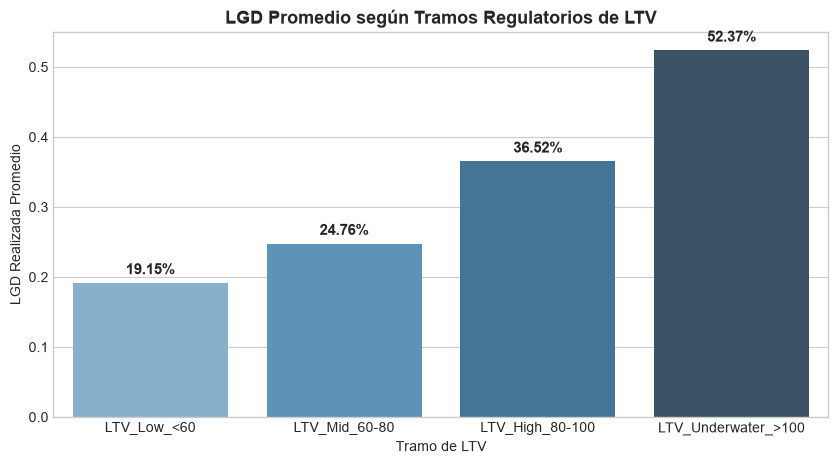

,LTV_bucket,count,mean_lgd,median_lgd,std_lgd
0,LTV_Low_<60,524,0.191499,0.038406,0.294925
1,LTV_Mid_60-80,267,0.247650,0.082833,0.299118
2,LTV_High_80-100,330,0.365223,0.242596,0.353896
3,LTV_Underwater_>100,332,0.523741,0.528689,0.350213


In [4]:
# Análisis de Tramos Regulatorios de LTV
bucket_summary = train_feat.groupby('LTV_bucket', observed=True)['lgd_time'].agg(
    count='count',
    mean_lgd='mean',
    median_lgd='median',
    std_lgd='std'
).reset_index()

fig, ax = plt.subplots(figsize=(10, 5))
sns.barplot(data=bucket_summary, x='LTV_bucket', y='mean_lgd', palette='Blues_d', ax=ax)
ax.set_title("LGD Promedio según Tramos Regulatorios de LTV", fontsize=13, fontweight='bold')
ax.set_xlabel("Tramo de LTV")
ax.set_ylabel("LGD Realizada Promedio")
for p in ax.patches:
    ax.annotate(f"{p.get_height():.2%}", (p.get_x() + p.get_width() / 2., p.get_height()),
                ha='center', va='bottom', fontsize=11, fontweight='bold', xytext=(0, 4), textcoords='offset points')
plt.show()

display(bucket_summary)

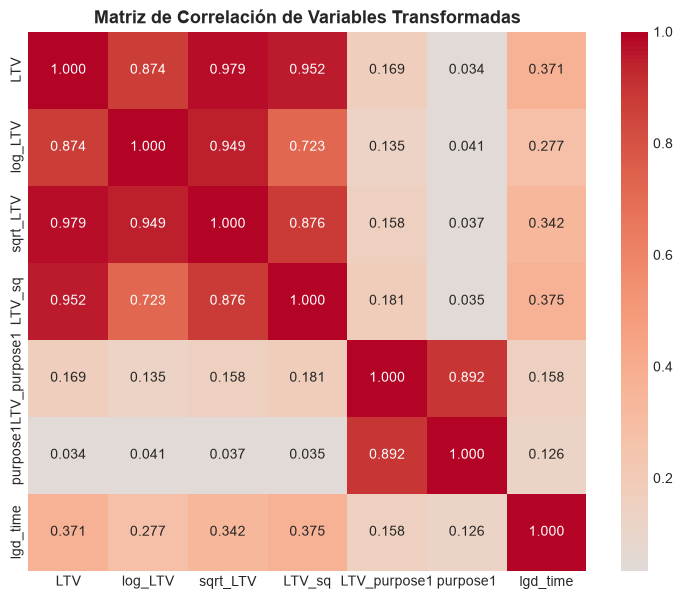

In [5]:
# Matriz de correlación de variables generadas
numeric_feats = ['LTV', 'log_LTV', 'sqrt_LTV', 'LTV_sq', 'LTV_purpose1', 'purpose1', 'lgd_time']
corr_matrix = train_feat[numeric_feats].corr()

plt.figure(figsize=(9, 7))
sns.heatmap(corr_matrix, annot=True, fmt='.3f', cmap='coolwarm', center=0, cbar=True)
plt.title("Matriz de Correlación de Variables Transformadas", fontsize=13, fontweight='bold')
plt.show()

In [6]:
# Exportar conjuntos de datos finales
train_feat.to_csv("../data/processed/lgd_train_features.csv", index=False)
test_feat.to_csv("../data/processed/lgd_test_features.csv", index=False)
print("Guardados datasets con variables de modelado en data/processed.")

Guardados datasets con variables de modelado en data/processed.


## Conclusiones Clave
1. **Monotonía Verificada**: La LGD aumenta de forma monotónica a través de los tramos de LTV (de 23% a más de 54%).
2. **Siguiente Cuaderno**: En el Cuaderno 04 entrenamos y contrastamos los modelos Champion y Challenger.